# fydp-3 — Multimodal Fusion + Demographics, Single Split, 20 Epochs

**Reverts the training regime from 5-fold cross-validation back to a normal single train/val/test
split, trained for 20 epochs per fusion type** — same compute budget/style as the original
single-split notebook (`quick_run`, 20 epochs) — while **keeping** the two additions from the CV
notebook that don't depend on cross-validation:

1. **Demographic + symptom fusion.** Age, Sex, and 8 binary symptom flags from `metadata.csv`,
   encoded by `DemoEncoder` and fused as a 4th modality token alongside yemas/palmas/unas
   embeddings (unchanged from the CV notebook).
2. **Tabular-only sklearn baselines** (Logistic Regression, Random Forest) on the same
   demographic/symptom features, evaluated on the identical held-out test set (unchanged in
   spirit — now fit on `train_df` alone instead of the combined `trainval_df` pool, matching the
   single-split structure below).

**Removed** (these only make sense with multiple folds, and this notebook now trains each fusion
type exactly once): the `StratifiedKFold` loop, the per-fold "ensemble" confusion-matrix/ROC
averaging, and the paired permutation significance test. Step 12's evaluation plots now show each
fusion type's single confusion matrix / ROC curve directly, and the per-class metrics in Step 9's
`evaluate()` come straight from that one run — nothing is skipped or approximated.

Split usage: `Split == "train"` trains the model, `Split == "validation"` picks the best epoch
checkpoint (highest val macro-F1), `Split == "test"` is the untouched final evaluation set — the
same 3-way split the very first single-split notebook used, just with the 4th (demographic)
modality token added on top.


## Step 1 — Imports & GPU Setup

No Drive mount needed on Kaggle — inputs are already mounted at `/kaggle/input/`.

In [30]:
import os
import json
import random
from datetime import datetime

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, auc as sk_auc,
                              confusion_matrix, ConfusionMatrixDisplay,
                              precision_recall_fscore_support)
from sklearn.preprocessing import label_binarize, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

random.seed(42); np.random.seed(42); torch.manual_seed(42)

# --- GPU setup (Kaggle "GPU T4 x2" = two physical T4s visible to this container) ---
N_GPUS = torch.cuda.device_count() if torch.cuda.is_available() else 0
DEVICE = torch.device("cuda" if N_GPUS > 0 else "cpu")
USE_MULTI_GPU = N_GPUS > 1   # quick_run() wraps the model in nn.DataParallel when True

print("Using device:", DEVICE)
if N_GPUS > 0:
    for i in range(N_GPUS):
        print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")
print(f"USE_MULTI_GPU = {USE_MULTI_GPU}  ({N_GPUS} GPU(s) visible)")
if N_GPUS == 0:
    print("WARNING: no GPU visible - set Accelerator -> GPU T4 x2 in the notebook settings panel and restart.")


Using device: cuda
  GPU 0: Tesla T4
  GPU 1: Tesla T4
USE_MULTI_GPU = True  (2 GPU(s) visible)


## Step 1.5 — See What Kaggle Actually Mounted (run this first)

Prints the real folder tree under `/kaggle/input` up to 3 levels deep. Copy
the exact paths you see here into the manual override section in Step 2 —
this sidesteps auto-detection entirely, so there's no more guessing.

In [31]:
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.count(os.sep) - "/kaggle/input".count(os.sep)
    if depth > 3:
        dirs[:] = []
        continue
    indent = "  " * depth
    print(f"{indent}{os.path.basename(root) or root}/")
    for fn in sorted(files):
        print(f"{indent}  {fn}")


input/
  datasets/
    shimu080/
      metadata/
        metadata.csv
      unas-palmas-yemas/
      dataset2/
        Dataset2.csv


## Step 2 — Config: Paths & Settings (manual paths, with auto-detect fallback)

**Fill in `MANUAL_PATHS` below using what Step 1.5 printed.** Same as the prior two notebooks,
plus new settings for demographic fusion, K-Fold CV, and the permutation test.

`RESULTS_DIR` lives under `/kaggle/working/` — the only writable location on
Kaggle (`/kaggle/input/` is strictly read-only).

In [32]:
# --- Manual path overrides ---
# Copy the exact paths from the Step 1.5 output above. Example, if Step 1.5 printed:
#   yemas_frames/
#     yemas_frames/
#       Leve/
#       Moderada/
#       Normal/
# then the path you want is "/kaggle/input/yemas_frames/yemas_frames" (the
# folder that directly CONTAINS Leve/Moderada/Normal, not the folder above it).
MANUAL_PATHS = {
    "metadata": "/kaggle/input/datasets/shimu080/metadata/metadata.csv",  
    "csv":    "/kaggle/input/datasets/shimu080/dataset2/Dataset2.csv",                     # <-- EDIT: exact path to Dataset2.csv
    "yemas":  "/kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames",                 # <-- EDIT
    "palmas": "/kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames",            # <-- EDIT
    "unas":   "/kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images",             # <-- EDIT
}
KAGGLE_INPUT_ROOT = "/kaggle/input"
RESULTS_DIR_ROOT = "/kaggle/working"
_available_inputs = sorted(os.listdir(KAGGLE_INPUT_ROOT)) if os.path.isdir(KAGGLE_INPUT_ROOT) else []

def find_input_dataset(*keywords):
    """Auto-detect fallback: first folder directly under /kaggle/input whose
    name contains any of the given keywords. Only used when the matching
    MANUAL_PATHS entry above is None."""
    for entry in _available_inputs:
        full = os.path.join(KAGGLE_INPUT_ROOT, entry)
        if os.path.isdir(full) and any(k in entry.lower() for k in keywords):
            return full
    return None

def descend_if_nested(base, *keywords):
    if base is None or not os.path.isdir(base):
        return base
    for child in sorted(os.listdir(base)):
        child_path = os.path.join(base, child)
        if os.path.isdir(child_path) and any(k in child.lower() for k in keywords):
            if any(os.path.isdir(os.path.join(child_path, g)) for g in os.listdir(child_path)):
                return child_path
    return base

def find_csv_in(base):
    if base is None or not os.path.isdir(base):
        return None
    for f in sorted(os.listdir(base)):
        if f.lower().endswith(".csv"):
            return os.path.join(base, f)
    return None

# Manual path wins if set; otherwise fall back to auto-detection.
SPLIT_CSV_PATH = MANUAL_PATHS["csv"] or find_csv_in(find_input_dataset("dataset2", "dataset"))
METADATA_CSV_PATH = MANUAL_PATHS["metadata"] or SPLIT_CSV_PATH
YEMAS_DIR  = MANUAL_PATHS["yemas"]  or descend_if_nested(find_input_dataset("yemas"), "yemas")
PALMAS_DIR = MANUAL_PATHS["palmas"] or descend_if_nested(find_input_dataset("palmas", "palma"), "palmas", "palma")
UNAS_DIR   = MANUAL_PATHS["unas"]   or descend_if_nested(find_input_dataset("unas"), "unas")
FALLBACK_METADATA_CSV = SPLIT_CSV_PATH  # same source on Kaggle, kept for Step 4 compatibility

# Dedicated results folder in the writable Kaggle output area.
STAMP_RESULTS_BY_DATE = True
_run_date = datetime.now().strftime("%Y-%m-%d")
RESULTS_DIR = os.path.join(RESULTS_DIR_ROOT, "fydp-3_results", "singlesplit_demo_fusion_test")
if STAMP_RESULTS_BY_DATE:
    RESULTS_DIR = os.path.join(RESULTS_DIR, _run_date)
os.makedirs(RESULTS_DIR, exist_ok=True)

EXPECTED_FRAME_COUNTS = {"yemas": 32, "palmas": 16}  # frames SAMPLED from each subject's extracted-frame folder
FRAME_IMAGE_EXTS = (".jpg", ".jpeg", ".png")          # extracted yemas/palmas frame files
IMAGE_EXTS = (".jpg", ".jpeg", ".png")                # single cropped unas nail image

# Folder-name template for each subject's extracted frames, relative to
# <modality_dir>/<Class>/ . Default assumes .../yemas_frames/<Class>/<ID>/frame_0001.jpg etc.
# Edit if your frames sit in a differently-named subfolder, e.g. "{id}_frames".
FRAME_FOLDER_TEMPLATE = "{id}"

# --- Multi-class label setup ---
CLASS_TO_IDX = {"Normal": 0, "Leve": 1, "Moderada": 2}
IDX_TO_CLASS = {v: k for k, v in CLASS_TO_IDX.items()}
NUM_CLASSES = len(CLASS_TO_IDX)

# --- Run settings (single-split leftovers, kept for the tabular-baseline section) ---
SUBSET_SIZE = None     # None = use the full split file; set a number for a faster partial run
BATCH_SIZE = 16 if USE_MULTI_GPU else 8   # bumped for 2x T4 so both GPUs stay fed
TEMPORAL_POOLING = "mean"   # "mean" or "bilstm"

# --- Single-split training settings (replaces the 5-fold CV settings) ---
QUICK_EPOCHS = 20        # epochs per fusion type, single train/val/test split - matches the
                         # original single-split notebook's compute budget.

# --- NEW: Demographic / symptom columns to fuse in as a 4th modality token ---
# Left side = internal standardized name used throughout this notebook.
# Right side = candidate column names to look for in metadata.csv (case-insensitive substring
# match), covering the English names from the dataset info doc and likely Spanish originals.
DEMO_NUMERIC_CANDIDATES = {
    "age": ["age", "edad"],
    "heart_rate": ["heart rate", "frecuencia cardiaca", "frecuencia_cardiaca", "heartrate"],
    "spo2": ["spo2", "spo 2", "oxygen saturation", "oxigeno", "saturacion"],
    "weight": ["weight", "peso"],
    "height": ["height", "talla"],
}
DEMO_BINARY_CANDIDATES = {
    "sex": ["sex", "sexo", "gender"],  # mapped M/F -> 1/0 below, not z-scored
}
SYMPTOM_CANDIDATES = {
    "fatigue": ["fatigue", "fatiga"],
    "weakness": ["weakness", "debilidad"],
    "irregular_heartbeat": ["irregular heartbeat", "latidos irregulares"],
    "shortness_of_breath": ["shortness of breath", "dificultad para respirar", "dificultad_para_respirar"],
    "dizziness": ["dizziness", "mareos"],
    "chest_pain": ["chest pain", "dolor en el pecho", "dolor_en_el_pecho"],
    "cold_hands_feet": ["cold hands", "manos y pies frios", "manos_y_pies_frios"],
    "headache": ["headache", "dolores de cabeza", "dolores_de_cabeza"],
}

print("SPLIT_CSV_PATH:", SPLIT_CSV_PATH or "NOT FOUND")
print("METADATA_CSV_PATH:", METADATA_CSV_PATH or "NOT FOUND")
print("YEMAS_DIR     :", YEMAS_DIR or "NOT FOUND")
print("PALMAS_DIR    :", PALMAS_DIR or "NOT FOUND")
print("UNAS_DIR      :", UNAS_DIR or "NOT FOUND")
print("RESULTS_DIR   :", RESULTS_DIR, "(writable Kaggle output area)")
print("CLASS_TO_IDX  :", CLASS_TO_IDX)
print(f"QUICK_EPOCHS={QUICK_EPOCHS}  BATCH_SIZE={BATCH_SIZE}  TEMPORAL_POOLING={TEMPORAL_POOLING}")
if not (SPLIT_CSV_PATH and YEMAS_DIR and PALMAS_DIR and UNAS_DIR):
    print("\nSome paths above are NOT FOUND. Check the MANUAL_PATHS dict against the "
          "Step 1.5 output and fix the ones that don't match.")


SPLIT_CSV_PATH: /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv
METADATA_CSV_PATH: /kaggle/input/datasets/shimu080/metadata/metadata.csv
YEMAS_DIR     : /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
PALMAS_DIR    : /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
UNAS_DIR      : /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
RESULTS_DIR   : /kaggle/working/fydp-3_results/singlesplit_demo_fusion_test/2026-10-22 (writable Kaggle output area)
CLASS_TO_IDX  : {'Normal': 0, 'Leve': 1, 'Moderada': 2}
QUICK_EPOCHS=20  BATCH_SIZE=16  TEMPORAL_POOLING=mean


## Step 3 — Verify Resolved Dataset Paths

Asserts each path from Step 2 (manual or auto-detected) was actually found
and prints the class folders inside it, so a bad path is obvious immediately
instead of after a long training run.

In [33]:
for label, d in [("YEMAS", YEMAS_DIR), ("PALMAS", PALMAS_DIR), ("UNAS", UNAS_DIR)]:
    assert d is not None and os.path.isdir(d), (
        f"{label}_DIR not found at: {d}\n"
        f"Fix MANUAL_PATHS['{label.lower()}'] in Step 2 - copy the exact path from the "
        f"Step 1.5 listing above (the folder that directly contains Leve/Moderada/Normal)."
    )
    classes = [c for c in os.listdir(d) if os.path.isdir(os.path.join(d, c))]
    print(f"{label}_DIR -> {d}")
    print(f"  class folders found = {classes}")

assert SPLIT_CSV_PATH is not None and os.path.isfile(SPLIT_CSV_PATH), (
    f"Split CSV not found at: {SPLIT_CSV_PATH}\n"
    f"Fix MANUAL_PATHS['csv'] in Step 2 - copy the exact path to Dataset2.csv from the "
    f"Step 1.5 listing above."
)
print("\nSPLIT_CSV_PATH ->", SPLIT_CSV_PATH)


YEMAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
  class folders found = ['Leve', 'Moderada', 'Normal']
PALMAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
  class folders found = ['Leve', 'Moderada', 'Normal']
UNAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
  class folders found = ['Leve', 'Moderada', 'Normal']

SPLIT_CSV_PATH -> /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv


## Step 4 — Load Split File + Metadata (Class label + demographic/symptom features)

Same `Class`-derivation fix as the prior two notebooks: `Dataset2.csv`'s own `Class` column is
row-shifted for IDs 058-227, so `Class` is re-derived from `metadata.csv`'s `Normal`/`Leve`/
`Moderado` one-hot columns instead.

**New in this notebook:** also builds a **demographic/symptom feature matrix** from `metadata.csv`
— Age, Sex, and 8 binary symptom flags — used both by the deep model's `DemoEncoder` (Step 8) and
by the standalone sklearn tabular baselines (Step 7). Column names in the raw CSV may be in
Spanish or English; `resolve_columns()` below auto-detects whichever variant is present via
case-insensitive substring matching against `DEMO_NUMERIC_CANDIDATES` / `DEMO_BINARY_CANDIDATES` /
`SYMPTOM_CANDIDATES` from Step 2, and **prints exactly which columns were found vs. missing** so
you can sanity-check the auto-detection or hand-edit the candidate lists in Step 2 if a column is
misdetected.

In [34]:
if os.path.isfile(SPLIT_CSV_PATH):
    metadata_source = SPLIT_CSV_PATH
elif os.path.isfile(FALLBACK_METADATA_CSV):
    metadata_source = FALLBACK_METADATA_CSV
    print(f"SPLIT_CSV_PATH not found - falling back to {FALLBACK_METADATA_CSV}")
else:
    raise FileNotFoundError(
        f"Could not find a metadata/split file at either:\n  {SPLIT_CSV_PATH}\n  {FALLBACK_METADATA_CSV}\n"
        f"Attach the dataset containing your split CSV as a Kaggle Input, or fix SPLIT_CSV_PATH in Step 2."
    )
if not os.path.isfile(METADATA_CSV_PATH):
    raise FileNotFoundError(
        f"Could not find metadata.csv (source of Class one-hot + demographics) at:\n  {METADATA_CSV_PATH}\n"
        f"Fix MANUAL_PATHS['metadata'] in Step 2."
    )

print("Using split file:", metadata_source)
print("Using metadata file (Class one-hot + demographics/symptoms):", METADATA_CSV_PATH)

split_df = pd.read_csv(metadata_source)
split_df = split_df.dropna(subset=["ID"]).copy()
split_df["ID"] = split_df["ID"].astype(str).str.strip()
assert "Split" in split_df.columns, "Split column missing from Dataset2.csv - cannot preserve the existing split."
split_df["Split"] = split_df["Split"].astype(str).str.strip()
# NOTE: Dataset2.csv's own "Class" / "Anemia Predict" columns are intentionally NOT used below -
# "Class" was found to be row-shifted/misaligned for IDs 058-227 during verification.
split_df = split_df[["ID", "Split"]]

meta_df = pd.read_csv(METADATA_CSV_PATH)
meta_df["ID"] = meta_df["ID"].astype(str).str.strip()
required_meta_cols = ["ID", "Normal", "Leve", "Moderado", "Hemoglobina"]
missing_meta_cols = [c for c in required_meta_cols if c not in meta_df.columns]
assert not missing_meta_cols, f"metadata.csv is missing required columns: {missing_meta_cols}"

def _derive_class(row):
    if row["Normal"] == 1:
        return "Normal"
    if row["Leve"] == 1:
        return "Leve"
    if row["Moderado"] == 1:
        return "Moderada"
    return None

meta_df["Class"] = meta_df.apply(_derive_class, axis=1)
assert meta_df["Class"].notna().all(), "Some metadata rows have no Normal/Leve/Moderado flag set - cannot derive Class."

# Drop physiologically-impossible Hemoglobina values (data-entry errors) - these rows are unreliable
# regardless of target, so they're dropped rather than silently corrected/guessed.
HB_MIN_PLAUSIBLE, HB_MAX_PLAUSIBLE = 3.0, 20.0
outlier_mask = (meta_df["Hemoglobina"] < HB_MIN_PLAUSIBLE) | (meta_df["Hemoglobina"] > HB_MAX_PLAUSIBLE)
n_outliers = int(outlier_mask.sum())
if n_outliers:
    print(f"Dropping {n_outliers} subject(s) with implausible Hemoglobina values "
          f"(outside [{HB_MIN_PLAUSIBLE}, {HB_MAX_PLAUSIBLE}] g/dL):")
    print(meta_df.loc[outlier_mask, ["ID", "Hemoglobina"]].to_string(index=False))
meta_df = meta_df.loc[~outlier_mask].reset_index(drop=True)

meta_df["Label"] = meta_df["Class"].map(CLASS_TO_IDX)
assert meta_df["Label"].notna().all(), "Some Class values did not map via CLASS_TO_IDX - check spelling/casing."
meta_df["Label"] = meta_df["Label"].astype(int)

# --- NEW: resolve demographic/symptom column names (English or Spanish) by substring match ---
def resolve_columns(df, candidates_map):
    """For each standardized name -> list of candidate substrings, find the first matching real
    column in df (case-insensitive substring match). Returns {standard_name: real_col_or_None}."""
    resolved = {}
    lower_cols = {c.lower(): c for c in df.columns}
    for std_name, candidates in candidates_map.items():
        found = None
        for cand in candidates:
            for lc, real in lower_cols.items():
                if cand.lower() in lc:
                    found = real
                    break
            if found:
                break
        resolved[std_name] = found
    return resolved

numeric_resolved = resolve_columns(meta_df, DEMO_NUMERIC_CANDIDATES)
binary_resolved = resolve_columns(meta_df, DEMO_BINARY_CANDIDATES)
symptom_resolved = resolve_columns(meta_df, SYMPTOM_CANDIDATES)

print("\nDemographic column detection:")
for std_name, real in {**numeric_resolved, **binary_resolved}.items():
    print(f"  {std_name:20s} -> {real if real else 'NOT FOUND (will be excluded / imputed)'}")
print("Symptom column detection:")
for std_name, real in symptom_resolved.items():
    print(f"  {std_name:20s} -> {real if real else 'NOT FOUND (will be excluded / imputed)'}")

# Build a compact demographic/symptom feature table, one row per subject (indexed by ID).
demo_feature_cols = []
demo_table = pd.DataFrame({"ID": meta_df["ID"]})

for std_name, real in numeric_resolved.items():
    if real is not None:
        demo_table[std_name] = pd.to_numeric(meta_df[real], errors="coerce")
        demo_feature_cols.append(std_name)

for std_name, real in binary_resolved.items():
    if real is not None and std_name == "sex":
        # Map to 1/0; tolerant of "M"/"F", "Male"/"Female", 1/0 already, etc.
        raw = meta_df[real].astype(str).str.strip().str.upper()
        demo_table["sex"] = raw.map(lambda v: 1 if v.startswith("M") else (0 if v.startswith("F") else np.nan))
        demo_feature_cols.append("sex")

for std_name, real in symptom_resolved.items():
    if real is not None:
        demo_table[std_name] = pd.to_numeric(meta_df[real], errors="coerce").fillna(0).clip(0, 1)
        demo_feature_cols.append(std_name)

# Impute any remaining missing numeric values with the column median (computed once, globally,
# for simplicity - fold-specific re-imputation would be more rigorous but adds complexity for a
# small number of likely-rare missing values).
for col in demo_feature_cols:
    if demo_table[col].isna().any():
        med = demo_table[col].median()
        n_missing = int(demo_table[col].isna().sum())
        print(f"Imputing {n_missing} missing value(s) in '{col}' with median={med:.2f}")
        demo_table[col] = demo_table[col].fillna(med)

DEMO_FEATURE_COLS = demo_feature_cols
print(f"\nFinal demographic/symptom feature columns used ({len(DEMO_FEATURE_COLS)}): {DEMO_FEATURE_COLS}")
if len(DEMO_FEATURE_COLS) == 0:
    print("WARNING: no demographic/symptom columns were detected - demographic fusion and the "
          "tabular baselines will not be meaningful. Check metadata.csv's actual column names "
          "against DEMO_NUMERIC_CANDIDATES / DEMO_BINARY_CANDIDATES / SYMPTOM_CANDIDATES in Step 2.")

# Merge: keep the ORIGINAL Split assignment (from Dataset2.csv), attach corrected Class/Label and
# the demographic feature table.
metadata_df = split_df.merge(meta_df[["ID", "Class", "Label"]], on="ID", how="inner")
metadata_df = metadata_df.merge(demo_table, on="ID", how="left")
n_dropped_no_meta = len(split_df) - len(metadata_df)
if n_dropped_no_meta:
    print(f"NOTE: {n_dropped_no_meta} subject(s) in the split file had no matching metadata row "
          f"(dropped due to outlier removal above, or ID not present in metadata.csv).")

has_split_col = True
print(f"\n{len(metadata_df)} subjects with a valid Split + Class label + demographic features.")
print(metadata_df["Split"].value_counts())
print("\nClass distribution:")
print(metadata_df["Class"].value_counts())


Using split file: /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv
Using metadata file (Class one-hot + demographics/symptoms): /kaggle/input/datasets/shimu080/metadata/metadata.csv
Dropping 2 subject(s) with implausible Hemoglobina values (outside [3.0, 20.0] g/dL):
   ID  Hemoglobina
ID645        123.0
ID843        140.0

Demographic column detection:
  age                  -> Edad
  heart_rate           -> Frecuencia Cardiaca
  spo2                 -> NOT FOUND (will be excluded / imputed)
  weight               -> Peso
  height               -> Talla
  sex                  -> Sexo
Symptom column detection:
  fatigue              -> Fatiga
  weakness             -> Debilidad
  irregular_heartbeat  -> Latidos irregulares
  shortness_of_breath  -> Dificultad para respirar
  dizziness            -> Mareos o aturdimiento
  chest_pain           -> Dolor en el pecho
  cold_hands_feet      -> NOT FOUND (will be excluded / imputed)
  headache             -> Dolores de cabeza
Imputing 2

## Step 5 — Existence Check + Build Fixed Train / Validation / Test Split

- Existence check (per-subject, all 3 modality files present) is unchanged.
- **Reverted to the single-split structure:** `Split == "train"` / `"validation"` / `"test"` become
  three separate, patient-level-disjoint DataFrames (`train_df`, `val_df`, `test_df`) instead of
  being pooled into a `trainval_df` for K-Fold re-splitting.
- The demographic `StandardScaler` and the inverse-frequency class weights are now each fit **once**
  on `train_df` only (no per-fold refitting, since there's only one fold now) and reused by every
  cell downstream.


In [35]:
def subject_frame_folder(modality_dir, subj_class, subj_id):
    """Path to a subject's extracted-frame folder, e.g. dataset/yemas/<Class>/<ID>/."""
    folder_name = FRAME_FOLDER_TEMPLATE.format(id=subj_id)
    return os.path.join(modality_dir, subj_class, folder_name)

def list_frame_files(folder):
    """All extracted frame image paths in a subject's folder, sorted by filename."""
    if not os.path.isdir(folder):
        return []
    files = sorted(f for f in os.listdir(folder) if f.lower().endswith(FRAME_IMAGE_EXTS))
    return [os.path.join(folder, f) for f in files]

def find_subject_file(modality_dir, subj_class, subj_id, exts):
    for ext in exts:
        p = os.path.join(modality_dir, subj_class, subj_id + ext)
        if os.path.isfile(p):
            return p
    return None

def subject_exists(subj_id, subj_class):
    y = len(list_frame_files(subject_frame_folder(YEMAS_DIR, subj_class, subj_id))) > 0
    p = len(list_frame_files(subject_frame_folder(PALMAS_DIR, subj_class, subj_id))) > 0
    u = find_subject_file(UNAS_DIR, subj_class, subj_id, IMAGE_EXTS) is not None
    return y and p and u

tqdm.pandas(desc="Checking files exist")
metadata_df["exists_all_3"] = metadata_df.progress_apply(
    lambda r: subject_exists(r["ID"], r["Class"]), axis=1
)
usable_df = metadata_df[metadata_df["exists_all_3"]].reset_index(drop=True)
print(f"\n{len(usable_df)} / {len(metadata_df)} subjects have all 3 modality inputs on disk.")

if len(usable_df) == 0:
    sample_row = metadata_df.iloc[0]
    example_path = subject_frame_folder(YEMAS_DIR, sample_row["Class"], sample_row["ID"])
    raise RuntimeError(
        f"No subjects passed the existence check. Example frame folder tried:\n  {example_path}\n"
        f"Check DATASET_DIR / folder names in Steps 2-3, and confirm your extracted frames sit at "
        f"dataset/<modality>/<Class>/<ID>/*.jpg (edit FRAME_FOLDER_TEMPLATE in Step 2 if your subfolder "
        f"naming differs). Class folders found there were printed above, compare against Class values in "
        f"your metadata (e.g. '{sample_row['Class']}')."
    )

if SUBSET_SIZE is not None and len(usable_df) > SUBSET_SIZE:
    from sklearn.model_selection import train_test_split as _tts
    usable_df, _ = _tts(usable_df, train_size=SUBSET_SIZE, stratify=usable_df["Class"], random_state=42)
    usable_df = usable_df.reset_index(drop=True)
    print(f"Subsampled down to {len(usable_df)} subjects (SUBSET_SIZE set).")

assert has_split_col, "Step 4 requires the Split column from Dataset2.csv to exist."
train_df = usable_df[usable_df["Split"] == "train"].reset_index(drop=True)
val_df = usable_df[usable_df["Split"] == "validation"].reset_index(drop=True)
test_df = usable_df[usable_df["Split"] == "test"].reset_index(drop=True)

train_ids, val_ids, test_ids = set(train_df["ID"]), set(val_df["ID"]), set(test_df["ID"])
assert train_ids.isdisjoint(val_ids) and train_ids.isdisjoint(test_ids) and val_ids.isdisjoint(test_ids), (
    "train/validation/test are not patient-level disjoint - check the Split column."
)
print("PASS: train, validation, and test are patient-level disjoint.")

print(f"\ntrain      = {len(train_df)}")
print(f"validation = {len(val_df)}")
print(f"test       = {len(test_df)}")
print("\ntrain class counts:\n", train_df["Class"].value_counts())
print("\nvalidation class counts:\n", val_df["Class"].value_counts())
print("\ntest class counts:\n", test_df["Class"].value_counts())

# --- Fit the demographic StandardScaler ONCE on train_df only (normal single-split setting: no
# per-fold refitting since there's only one split now). ---
if len(DEMO_FEATURE_COLS) > 0:
    DEMO_SCALER = StandardScaler().fit(train_df[DEMO_FEATURE_COLS].to_numpy(dtype=np.float64))
    print(f"\nDEMO_SCALER fit on {len(train_df)} train_df subjects, {len(DEMO_FEATURE_COLS)} feature(s).")
else:
    DEMO_SCALER = None

# --- Inverse-frequency class weights from train_df labels only, used by CrossEntropyLoss below. ---
_label_counts = train_df["Label"].value_counts().sort_index()
_counts = np.array([_label_counts.get(i, 0) for i in range(NUM_CLASSES)], dtype=np.float64)
_inv_freq = _counts.sum() / (NUM_CLASSES * np.clip(_counts, 1, None))
CLASS_WEIGHTS = torch.tensor(_inv_freq, dtype=torch.float32)
print(f"CLASS_WEIGHTS (inverse-frequency, from train_df): {CLASS_WEIGHTS.tolist()}")


Checking files exist:   0%|          | 0/907 [00:00<?, ?it/s]


808 / 907 subjects have all 3 modality inputs on disk.
PASS: train, validation, and test are patient-level disjoint.

train      = 562
validation = 123
test       = 123

train class counts:
 Class
Normal      375
Leve        138
Moderada     49
Name: count, dtype: int64

validation class counts:
 Class
Normal      83
Leve        26
Moderada    14
Name: count, dtype: int64

test class counts:
 Class
Normal      87
Leve        29
Moderada     7
Name: count, dtype: int64

DEMO_SCALER fit on 562 train_df subjects, 12 feature(s).
CLASS_WEIGHTS (inverse-frequency, from train_df): [0.4995555579662323, 1.3574879169464111, 3.823129177093506]


## Step 6 — Frame Sampling (Pre-Extracted) + Dataset Class (images + demographics + label)

Unchanged: frame sampling, resize, ImageNet normalization (32 yemas frames, 16 palmas frames,
evenly sampled, no on-the-fly video decoding).

`__getitem__` also returns a **demographic feature tensor** (`DEMO_FEATURE_COLS`), z-scored using
`DEMO_SCALER` from Step 5 — fit once on `train_df`, since there's only one split now (no per-fold
refitting).


In [36]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
frame_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

def sample_frame_paths(all_paths, n_frames):
    """Evenly sample n_frames image paths from an already-extracted frame
    folder. If fewer frames exist than n_frames, all are used (the caller
    pads the rest by repeating the last frame)."""
    if len(all_paths) == 0:
        return []
    if len(all_paths) <= n_frames:
        return all_paths
    indices = np.linspace(0, len(all_paths) - 1, n_frames).astype(int)
    return [all_paths[i] for i in indices]


class TriModalDataset(Dataset):
    """Now also yields a demographic feature vector alongside the 3 image modalities.

    `demo_scaler`: a fitted sklearn StandardScaler (fit on `train_df` only, see Step 5) used to
    z-score DEMO_FEATURE_COLS. Passing None skips scaling (raw values) - useful for a quick sanity
    check but not used in the main training run."""
    def __init__(self, df, transform, demo_scaler=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.demo_scaler = demo_scaler

    def __len__(self):
        return len(self.df)

    def _load_frame_sequence(self, modality_dir, subj_class, subj_id, n_frames):
        folder = subject_frame_folder(modality_dir, subj_class, subj_id)
        all_paths = list_frame_files(folder)
        chosen = sample_frame_paths(all_paths, n_frames)
        imgs = [self.transform(Image.open(p).convert("RGB")) for p in chosen]
        while len(imgs) < n_frames:  # defensive pad, e.g. a subject with fewer frames than expected
            imgs.append(imgs[-1].clone() if imgs else torch.zeros(3, 224, 224))
        return torch.stack(imgs)

    def _load_image(self, modality_dir, subj_class, subj_id):
        img_path = find_subject_file(modality_dir, subj_class, subj_id, IMAGE_EXTS)
        if img_path:
            return self.transform(Image.open(img_path).convert("RGB"))
        return torch.zeros(3, 224, 224)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        subj_id, subj_class = row["ID"], row["Class"]
        yemas = self._load_frame_sequence(YEMAS_DIR, subj_class, subj_id, EXPECTED_FRAME_COUNTS["yemas"])
        palmas = self._load_frame_sequence(PALMAS_DIR, subj_class, subj_id, EXPECTED_FRAME_COUNTS["palmas"])
        unas = self._load_image(UNAS_DIR, subj_class, subj_id)

        demo_raw = row[DEMO_FEATURE_COLS].to_numpy(dtype=np.float32).reshape(1, -1) if DEMO_FEATURE_COLS else np.zeros((1, 0), dtype=np.float32)
        if self.demo_scaler is not None and len(DEMO_FEATURE_COLS) > 0:
            demo_scaled = self.demo_scaler.transform(demo_raw).astype(np.float32).reshape(-1)
        else:
            demo_scaled = demo_raw.reshape(-1)
        demo = torch.from_numpy(demo_scaled)

        label = torch.tensor(int(row["Label"]), dtype=torch.long)
        return yemas, palmas, unas, demo, label

# Sanity check on one real subject before committing to a full run (no scaler here - raw values).
_sample_row = train_df.iloc[0]
_sample_ds = TriModalDataset(train_df.iloc[[0]], frame_transform, demo_scaler=None)
_y, _p, _u, _d, _l = _sample_ds[0]
print(f"Sanity check on subject {_sample_row['ID']}: yemas={tuple(_y.shape)} palmas={tuple(_p.shape)} "
      f"unas={tuple(_u.shape)} demo={tuple(_d.shape)} label={_l.item()} ({IDX_TO_CLASS[_l.item()]})")
print("TriModalDataset ready (loading pre-extracted frames + demographic features, no video decoding).")


Sanity check on subject ID001: yemas=(32, 3, 224, 224) palmas=(16, 3, 224, 224) unas=(3, 224, 224) demo=(12,) label=0 (Normal)
TriModalDataset ready (loading pre-extracted frames + demographic features, no video decoding).


## Step 7 — Tabular-Only Baselines (Logistic Regression, Random Forest)

Trains sklearn `LogisticRegression` and `RandomForestClassifier` on `DEMO_FEATURE_COLS` alone (Age,
Sex, 8 symptom flags — no images at all), evaluated on the same fixed `test_df` used for the deep
models. This directly answers "is the deep multimodal model actually adding value over structured
demographic/symptom data alone?"

Both models are fit on **`train_df`** (the single training split, not combined with validation) and
also given a 5-fold `cross_val_score` on `train_df` for robustness, since sklearn training is cheap
regardless of the deep-model training regime.


In [37]:
if len(DEMO_FEATURE_COLS) == 0:
    print("No demographic/symptom columns were detected in Step 4 - skipping tabular baselines.")
    tabular_results = {}
else:
    X_train = train_df[DEMO_FEATURE_COLS].to_numpy(dtype=np.float64)
    y_train = train_df["Label"].to_numpy()
    X_test = test_df[DEMO_FEATURE_COLS].to_numpy(dtype=np.float64)
    y_test = test_df["Label"].to_numpy()

    tab_scaler = StandardScaler().fit(X_train)
    X_train_scaled = tab_scaler.transform(X_train)
    X_test_scaled = tab_scaler.transform(X_test)

    tabular_models = {
        "tabular_logreg": LogisticRegression(max_iter=2000, class_weight="balanced", multi_class="multinomial"),
        "tabular_rf": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    }

    tabular_results = {}
    for name, clf in tabular_models.items():
        clf.fit(X_train_scaled, y_train)
        preds = clf.predict(X_test_scaled)
        probs = clf.predict_proba(X_test_scaled)

        acc = accuracy_score(y_test, preds)
        prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(
            y_test, preds, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0
        )
        prec_pc, rec_pc, f1_pc, support_pc = precision_recall_fscore_support(
            y_test, preds, labels=list(range(NUM_CLASSES)), average=None, zero_division=0
        )
        try:
            y_test_bin = label_binarize(y_test, classes=list(range(NUM_CLASSES)))
            auc_m = roc_auc_score(y_test_bin, probs, average="macro", multi_class="ovr")
        except ValueError:
            auc_m = float("nan")

        # 5-fold CV score on trainval alone, for robustness reporting (sklearn is cheap to re-fit).
        cv_f1 = cross_val_score(clf, X_train_scaled, y_train, cv=5, scoring="f1_macro")

        tabular_results[name] = {
            "accuracy": float(acc), "precision_macro": float(prec_m), "recall_macro": float(rec_m),
            "f1_macro": float(f1_m), "auc_macro_ovr": float(auc_m),
            "cv_f1_macro_mean": float(cv_f1.mean()), "cv_f1_macro_std": float(cv_f1.std()),
            "per_class_precision": prec_pc.tolist(), "per_class_recall": rec_pc.tolist(),
            "per_class_f1": f1_pc.tolist(), "per_class_support": support_pc.tolist(),
        }
        print(f"\n=== {name} ===")
        print(f"  Test accuracy={acc:.3f}  F1_macro={f1_m:.3f}  AUC_macro={auc_m:.3f}")
        print(f"  5-fold CV F1_macro on trainval: {cv_f1.mean():.3f} +/- {cv_f1.std():.3f}")
        for c in range(NUM_CLASSES):
            print(f"  [{IDX_TO_CLASS[c]:8s}] precision={prec_pc[c]:.3f}  recall={rec_pc[c]:.3f}  "
                  f"f1={f1_pc[c]:.3f}  support={support_pc[c]}")

    with open(os.path.join(RESULTS_DIR, "tabular_baseline_results.json"), "w") as f:
        json.dump(tabular_results, f, indent=2)



=== tabular_logreg ===
  Test accuracy=0.496  F1_macro=0.417  AUC_macro=0.711
  5-fold CV F1_macro on trainval: 0.450 +/- 0.044
  [Normal  ] precision=0.953  recall=0.471  f1=0.631  support=87
  [Leve    ] precision=0.340  recall=0.552  f1=0.421  support=29
  [Moderada] precision=0.121  recall=0.571  f1=0.200  support=7


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi


=== tabular_rf ===
  Test accuracy=0.650  F1_macro=0.323  AUC_macro=0.698
  5-fold CV F1_macro on trainval: 0.316 +/- 0.031
  [Normal  ] precision=0.704  recall=0.874  f1=0.779  support=87
  [Leve    ] precision=0.308  recall=0.138  f1=0.190  support=29
  [Moderada] precision=0.000  recall=0.000  f1=0.000  support=7


## Step 8 — Model Building Blocks (Encoders, Temporal Pool, Demographic Encoder, Fusion)

Image encoders/pooling are unchanged. **New:** `DemoEncoder`, a small MLP that projects the
demographic/symptom feature vector into the same `embed_dim` space as the image embeddings, so it
can be treated as a 4th "modality" token.

**Changed:** `ConcatFusion` and `SelfAttentionFusion` are generalized from a hardcoded 3 modalities
to accept **any number of modality tokens** (`forward(*embeddings)`), so the same fusion classes
serve both the image-only comparison (3 tokens) and the image+demographics comparison (4 tokens).

In [38]:
class FrameEncoder(nn.Module):
    def __init__(self, embed_dim=256):
        super().__init__()
        backbone = torchvision.models.resnet18(weights="IMAGENET1K_V1")
        self.backbone = nn.Sequential(*list(backbone.children())[:-1])
        self.proj = nn.Linear(512, embed_dim)

    def forward(self, x):
        return self.proj(self.backbone(x).flatten(1))


class DemoEncoder(nn.Module):
    """Projects a demographic/symptom feature vector into embed_dim, to be fused as a 4th
    modality token alongside the 3 image-derived embeddings."""
    def __init__(self, in_dim, embed_dim=256, dropout=0.3):
        super().__init__()
        if in_dim == 0:
            # No demographic columns detected - identity module producing a zero token, so the
            # rest of the pipeline (fusion expecting 4 tokens) still runs unchanged.
            self.net = None
            self.embed_dim = embed_dim
        else:
            self.net = nn.Sequential(
                nn.Linear(in_dim, embed_dim), nn.ReLU(), nn.Dropout(dropout),
                nn.Linear(embed_dim, embed_dim),
            )
            self.embed_dim = embed_dim

    def forward(self, x):
        if self.net is None:
            return torch.zeros(x.shape[0], self.embed_dim, device=x.device)
        return self.net(x)


class TemporalPool(nn.Module):
    """mean: simple average over frames. bilstm: bidirectional LSTM, final
    hidden states concatenated + projected back to embed_dim."""
    def __init__(self, embed_dim=256, mode="mean", lstm_hidden=128):
        super().__init__()
        self.mode = mode
        if mode == "bilstm":
            self.lstm = nn.LSTM(embed_dim, lstm_hidden, batch_first=True, bidirectional=True)
            self.proj = nn.Linear(lstm_hidden * 2, embed_dim)

    def forward(self, x):
        if self.mode == "mean":
            return x.mean(dim=1)
        _, (h_n, _) = self.lstm(x)
        return self.proj(torch.cat([h_n[0], h_n[1]], dim=1))


class ConcatFusion(nn.Module):
    """Baseline: no learned cross-modal interaction. Generalized to N modality tokens."""
    def __init__(self, embed_dim=256, n_modalities=4):
        super().__init__()
        self.out_dim = embed_dim * n_modalities

    def forward(self, *embeddings):
        return torch.cat(embeddings, dim=1)


class SelfAttentionFusion(nn.Module):
    """Proposed: the N modality tokens attend to each other symmetrically. Generalized to N
    modality tokens (was hardcoded to 3)."""
    def __init__(self, embed_dim=256, n_modalities=4, num_heads=4, dropout=0.3):
        super().__init__()
        self.modality_embed = nn.Parameter(torch.randn(n_modalities, embed_dim) * 0.02)
        layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads,
                                            dim_feedforward=embed_dim * 2,
                                            dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=1)
        self.out_dim = embed_dim

    def forward(self, *embeddings):
        x = torch.stack(embeddings, dim=1) + self.modality_embed.unsqueeze(0)
        return self.encoder(x).mean(dim=1)

print("Model building blocks ready (image encoders + DemoEncoder + generalized N-modality fusion).")


Model building blocks ready (image encoders + DemoEncoder + generalized N-modality fusion).


## Step 9 — Full Model + Train/Eval Functions (Per-Class Metrics) + `quick_run`

`fydp_3Model`, `train_one_epoch`, and `evaluate` are unchanged from the CV notebook (4 encoders —
yemas, palmas, unas, demo — feeding the fusion module; per-class precision/recall/F1/support
alongside the macro-averaged metrics).

**New:** `quick_run(fusion_name)` — brought back from the original single-split notebook, adapted
for the 4-modality multiclass model. Trains one fusion type for `QUICK_EPOCHS` epochs on
`train_df`, selects the best checkpoint by validation macro-F1, then evaluates once on `test_df`.
No folds, no re-fitting of scalers/weights per run — `DEMO_SCALER` and `CLASS_WEIGHTS` from Step 5
are reused as-is.


In [39]:
class fydp_3Model(nn.Module):
    def __init__(self, fusion="concat", temporal_pooling="mean", embed_dim=256, dropout=0.3,
                 num_classes=NUM_CLASSES, demo_in_dim=0):
        super().__init__()
        self.yemas_encoder = FrameEncoder(embed_dim)
        self.palmas_encoder = FrameEncoder(embed_dim)
        self.unas_encoder = FrameEncoder(embed_dim)
        self.demo_encoder = DemoEncoder(demo_in_dim, embed_dim, dropout=dropout)
        self.yemas_pool = TemporalPool(embed_dim, temporal_pooling)
        self.palmas_pool = TemporalPool(embed_dim, temporal_pooling)
        n_modalities = 4  # yemas, palmas, unas, demo
        self.fusion = (ConcatFusion(embed_dim, n_modalities) if fusion == "concat"
                       else SelfAttentionFusion(embed_dim, n_modalities, dropout=dropout))
        hidden = 128 if fusion == "concat" else 64
        self.classifier = nn.Sequential(
            nn.Linear(self.fusion.out_dim, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, num_classes)
        )

    def forward(self, yemas, palmas, unas, demo):
        B, Ty, C, H, W = yemas.shape
        _, Tp, _, _, _ = palmas.shape
        y = self.yemas_encoder(yemas.reshape(B * Ty, C, H, W)).view(B, Ty, -1)
        p = self.palmas_encoder(palmas.reshape(B * Tp, C, H, W)).view(B, Tp, -1)
        v_yemas, v_palmas = self.yemas_pool(y), self.palmas_pool(p)
        v_unas = self.unas_encoder(unas)
        v_demo = self.demo_encoder(demo)
        fused = self.fusion(v_yemas, v_palmas, v_unas, v_demo)
        return self.classifier(fused)  # raw logits, shape (B, NUM_CLASSES)


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total = 0.0
    for yemas, palmas, unas, demo, labels in tqdm(loader, desc="train", leave=False):
        yemas, palmas, unas, demo, labels = (yemas.to(DEVICE), palmas.to(DEVICE), unas.to(DEVICE),
                                              demo.to(DEVICE), labels.to(DEVICE))
        optimizer.zero_grad()
        loss = criterion(model(yemas, palmas, unas, demo), labels)
        loss.backward(); optimizer.step()
        total += loss.item() * len(labels)
    return total / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion):
    """Returns macro metrics (dict), predicted class indices, true labels, softmax probabilities,
    the confusion matrix, AND per-class precision/recall/F1/support (new)."""
    model.eval()
    total, probs_all, labels_all = 0.0, [], []
    for yemas, palmas, unas, demo, labels in tqdm(loader, desc="eval", leave=False):
        yemas, palmas, unas, demo, labels = (yemas.to(DEVICE), palmas.to(DEVICE), unas.to(DEVICE),
                                              demo.to(DEVICE), labels.to(DEVICE))
        logits = model(yemas, palmas, unas, demo)
        total += criterion(logits, labels).item() * len(labels)
        probs_all.append(F.softmax(logits, dim=1).cpu().numpy())
        labels_all.append(labels.cpu().numpy())
    probs, labels = np.concatenate(probs_all), np.concatenate(labels_all)
    preds = probs.argmax(axis=1)

    acc = accuracy_score(labels, preds)
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        labels, preds, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0
    )
    prec_pc, rec_pc, f1_pc, support_pc = precision_recall_fscore_support(
        labels, preds, labels=list(range(NUM_CLASSES)), average=None, zero_division=0
    )
    try:
        y_bin = label_binarize(labels, classes=list(range(NUM_CLASSES)))
        auc_macro = roc_auc_score(y_bin, probs, average="macro", multi_class="ovr")
    except ValueError:
        auc_macro = float("nan")

    cm = confusion_matrix(labels, preds, labels=list(range(NUM_CLASSES)))
    metrics = {
        "loss": total / len(loader.dataset),
        "accuracy": float(acc),
        "precision_macro": float(precision_macro),
        "recall_macro": float(recall_macro),
        "f1_macro": float(f1_macro),
        "auc_macro_ovr": float(auc_macro),
        "per_class_precision": prec_pc.tolist(),
        "per_class_recall": rec_pc.tolist(),
        "per_class_f1": f1_pc.tolist(),
        "per_class_support": support_pc.tolist(),
    }
    return metrics, preds, labels, probs, cm

def quick_run(fusion_name, temporal_pooling=TEMPORAL_POOLING, epochs=QUICK_EPOCHS):
    print(f"\n===== Run: fusion={fusion_name}  temporal_pooling={temporal_pooling}  epochs={epochs} =====")
    loader_kwargs = dict(num_workers=2, pin_memory=(DEVICE.type == "cuda"))
    train_loader = DataLoader(TriModalDataset(train_df, frame_transform, DEMO_SCALER),
                               batch_size=BATCH_SIZE, shuffle=True, **loader_kwargs)
    val_loader = DataLoader(TriModalDataset(val_df, frame_transform, DEMO_SCALER),
                             batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)
    test_loader = DataLoader(TriModalDataset(test_df, frame_transform, DEMO_SCALER),
                              batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)

    model = fydp_3Model(fusion=fusion_name, temporal_pooling=temporal_pooling,
                           demo_in_dim=len(DEMO_FEATURE_COLS)).to(DEVICE)
    if USE_MULTI_GPU:
        model = nn.DataParallel(model)
    criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE))
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    history = []
    best_val_f1, best_state = -float("inf"), None
    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        val_metrics, _, _, _, _ = evaluate(model, val_loader, criterion)
        history.append({"epoch": epoch, "train_loss": train_loss,
                         "val_loss": val_metrics["loss"], "val_f1_macro": val_metrics["f1_macro"]})
        print(f"Epoch {epoch}/{epochs}  train_loss={train_loss:.4f}  val_loss={val_metrics['loss']:.4f}  "
              f"val_F1_macro={val_metrics['f1_macro']:.3f}")
        if val_metrics["f1_macro"] == val_metrics["f1_macro"] and val_metrics["f1_macro"] > best_val_f1:
            best_val_f1 = val_metrics["f1_macro"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)

    test_metrics, test_preds, test_labels, test_probs, test_cm = evaluate(model, test_loader, criterion)
    print("\nFinal TEST metrics (best val-F1 checkpoint):")
    for k, v in test_metrics.items():
        if not k.startswith("per_class"):
            print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")
    for c in range(NUM_CLASSES):
        print(f"  [{IDX_TO_CLASS[c]:8s}] precision={test_metrics['per_class_precision'][c]:.3f}  "
              f"recall={test_metrics['per_class_recall'][c]:.3f}  f1={test_metrics['per_class_f1'][c]:.3f}  "
              f"support={test_metrics['per_class_support'][c]}")

    return model, pd.DataFrame(history), test_metrics, test_preds, test_labels, test_probs, test_cm

print("Training/eval utilities ready (single-split, 20-epoch runs, 4-modality multiclass model).")


Training/eval utilities ready (single-split, 20-epoch runs, 4-modality multiclass model).


## Step 10 — Train: Concatenation Fusion (baseline), 20 Epochs

In [41]:
(concat_model, concat_history, concat_test_metrics,
 concat_test_preds, concat_test_labels, concat_test_probs, concat_test_cm) = quick_run("concat")

concat_history.to_csv(os.path.join(RESULTS_DIR, "concat_history.csv"), index=False)
with open(os.path.join(RESULTS_DIR, "concat_test_metrics.json"), "w") as f:
    json.dump({k: v for k, v in concat_test_metrics.items()}, f, indent=2)
np.savez(os.path.join(RESULTS_DIR, "concat_test_raw.npz"),
         probs=concat_test_probs, labels=concat_test_labels)
torch.save(concat_model.state_dict(), os.path.join(RESULTS_DIR, "concat_model.pt"))
concat_history


===== Run: fusion=concat  temporal_pooling=mean  epochs=20 =====


train:   0%|          | 0/36 [00:00<?, ?it/s]

eval:   0%|          | 0/8 [00:00<?, ?it/s]

Epoch 1/20  train_loss=1.0391  val_loss=1.0883  val_F1_macro=0.385


train:   0%|          | 0/36 [00:00<?, ?it/s]

eval:   0%|          | 0/8 [00:00<?, ?it/s]

... (54 outputs left out)

Epoch 20/20  train_loss=0.0635  val_loss=1.8617  val_F1_macro=0.438


eval:   0%|          | 0/8 [00:00<?, ?it/s]


Final TEST metrics (best val-F1 checkpoint):
  loss: 1.2868
  accuracy: 0.6260
  precision_macro: 0.4565
  recall_macro: 0.4384
  f1_macro: 0.4404
  auc_macro_ovr: 0.6770
  [Normal  ] precision=0.768  recall=0.724  f1=0.746  support=87
  [Leve    ] precision=0.351  recall=0.448  f1=0.394  support=29
  [Moderada] precision=0.250  recall=0.143  f1=0.182  support=7


,epoch,train_loss,val_loss,val_f1_macro
0,1,1.039063,1.088332,0.384601
1,2,0.817262,1.308583,0.293831
2,3,0.590451,1.700626,0.335950
3,4,0.358003,1.326151,0.462410
4,5,0.189131,2.312574,0.296807
5,6,0.154744,2.767324,0.321772
6,7,0.219645,2.000661,0.374926
7,8,0.184544,2.248937,0.367121
8,9,0.151717,1.965296,0.418870
9,10,0.064675,2.637426,0.390995


## Step 11 — Train: Self-Attention Fusion (proposed), 20 Epochs

In [43]:
(selfattn_model, selfattn_history, selfattn_test_metrics,
 selfattn_test_preds, selfattn_test_labels, selfattn_test_probs, selfattn_test_cm) = quick_run("self_attention")

selfattn_history.to_csv(os.path.join(RESULTS_DIR, "self_attention_history.csv"), index=False)
with open(os.path.join(RESULTS_DIR, "self_attention_test_metrics.json"), "w") as f:
    json.dump({k: v for k, v in selfattn_test_metrics.items()}, f, indent=2)
np.savez(os.path.join(RESULTS_DIR, "self_attention_test_raw.npz"),
         probs=selfattn_test_probs, labels=selfattn_test_labels)
torch.save(selfattn_model.state_dict(), os.path.join(RESULTS_DIR, "self_attention_model.pt"))
selfattn_history


===== Run: fusion=self_attention  temporal_pooling=mean  epochs=20 =====


train:   0%|          | 0/36 [00:00<?, ?it/s]

eval:   0%|          | 0/8 [00:00<?, ?it/s]

Epoch 1/20  train_loss=1.0526  val_loss=0.9605  val_F1_macro=0.415


train:   0%|          | 0/36 [00:00<?, ?it/s]

eval:   0%|          | 0/8 [00:00<?, ?it/s]

... (54 outputs left out)

Epoch 20/20  train_loss=0.1092  val_loss=3.0251  val_F1_macro=0.312


eval:   0%|          | 0/8 [00:00<?, ?it/s]


Final TEST metrics (best val-F1 checkpoint):
  loss: 1.9660
  accuracy: 0.5772
  precision_macro: 0.3858
  recall_macro: 0.3771
  f1_macro: 0.3734
  auc_macro_ovr: 0.6563
  [Normal  ] precision=0.785  recall=0.713  f1=0.747  support=87
  [Leve    ] precision=0.320  recall=0.276  f1=0.296  support=29
  [Moderada] precision=0.053  recall=0.143  f1=0.077  support=7


,epoch,train_loss,val_loss,val_f1_macro
0,1,1.052640,0.960463,0.414969
1,2,0.916837,0.983266,0.419930
2,3,0.740947,1.716049,0.317849
3,4,0.574883,1.051172,0.437483
4,5,0.428875,1.829414,0.350088
5,6,0.367807,1.789331,0.343324
6,7,0.281658,1.401452,0.435796
7,8,0.235898,1.605534,0.398397
8,9,0.233045,1.897971,0.395135
9,10,0.302334,2.494616,0.336594


## Step 12 — Evaluation: Confusion Matrices + ROC Curves (Concat vs Self-Attention)

Side-by-side confusion matrices (concat left, self-attention right) and side-by-side one-vs-rest
ROC curves, both from the single 20-epoch run's test-set predictions — no fold-averaging needed
since there's only one model per fusion type now.


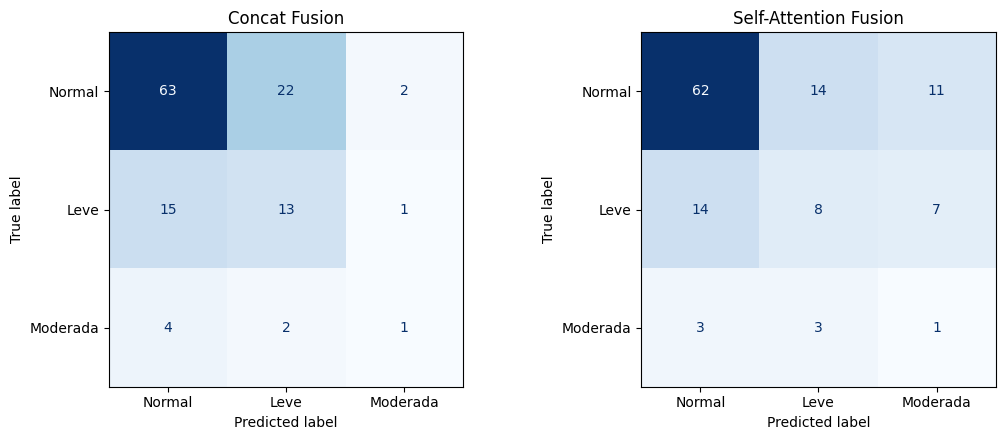

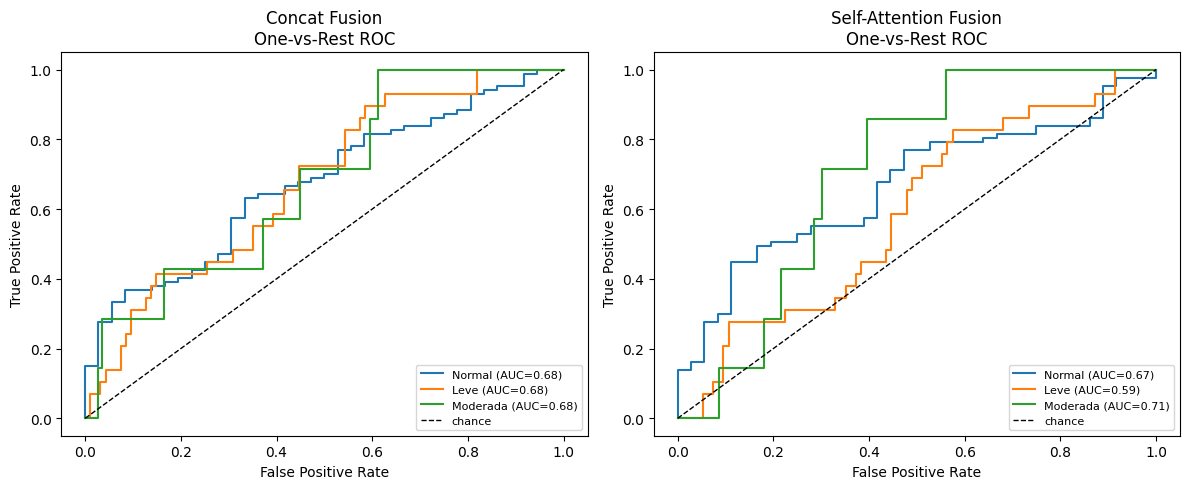

In [44]:
CLASS_NAMES = [IDX_TO_CLASS[i] for i in range(NUM_CLASSES)]

# --- Confusion matrices ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name, cm in [(axes[0], "Concat Fusion", concat_test_cm),
                      (axes[1], "Self-Attention Fusion", selfattn_test_cm)]:
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
cm_png = os.path.join(RESULTS_DIR, "confusion_matrices.png")
plt.savefig(cm_png, dpi=150, bbox_inches="tight")
plt.show()

# --- One-vs-rest ROC curves ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, probs, labels in [(axes[0], "Concat Fusion", concat_test_probs, concat_test_labels),
                                  (axes[1], "Self-Attention Fusion", selfattn_test_probs, selfattn_test_labels)]:
    y_bin = label_binarize(labels, classes=list(range(NUM_CLASSES)))
    for c in range(NUM_CLASSES):
        if y_bin[:, c].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_bin[:, c], probs[:, c])
        ax.plot(fpr, tpr, label=f"{CLASS_NAMES[c]} (AUC={sk_auc(fpr, tpr):.2f})")
    ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="chance")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"{name}\nOne-vs-Rest ROC")
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
roc_png = os.path.join(RESULTS_DIR, "roc_curves_ovr.png")
plt.savefig(roc_png, dpi=150, bbox_inches="tight")
plt.show()

Loss curves — concat vs self_attention (combined, single 20-epoch run)

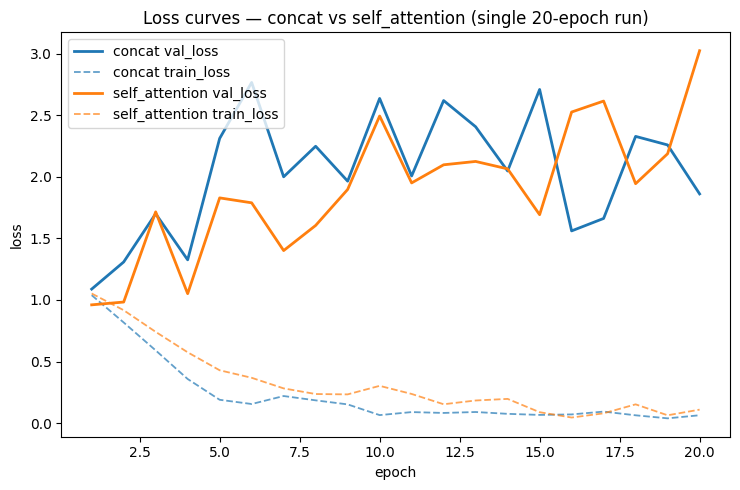

In [45]:
fig, ax = plt.subplots(figsize=(7.5, 5))

colors = {"concat": "tab:blue", "self_attention": "tab:orange"}

ax.plot(concat_history["epoch"], concat_history["val_loss"],
        color=colors["concat"], linestyle="-", linewidth=2, label="concat val_loss")
ax.plot(concat_history["epoch"], concat_history["train_loss"],
        color=colors["concat"], linestyle="--", linewidth=1.3, alpha=0.7, label="concat train_loss")
ax.plot(selfattn_history["epoch"], selfattn_history["val_loss"],
        color=colors["self_attention"], linestyle="-", linewidth=2, label="self_attention val_loss")
ax.plot(selfattn_history["epoch"], selfattn_history["train_loss"],
        color=colors["self_attention"], linestyle="--", linewidth=1.3, alpha=0.7, label="self_attention train_loss")

ax.set_xlabel("epoch")
ax.set_ylabel("loss")
ax.set_title(f"Loss curves \u2014 concat vs self_attention (single {QUICK_EPOCHS}-epoch run)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "loss_curves_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

## Step 13 — Final Comparison Table: Deep (Concat / Self-Attention) vs Tabular Baselines

Puts the single-run deep-model test metrics side by side with the sklearn tabular-only baselines
from Step 7 on the **same fixed test set**. Deep models have no cross-fold std (single run, so
`f1_macro_std = 0`); tabular baselines keep their 5-fold `cross_val_score` std from Step 7 for
context.


In [46]:
def deep_metrics_row(name, metrics):
    return {"model": name, "accuracy": metrics["accuracy"], "precision_macro": metrics["precision_macro"],
            "recall_macro": metrics["recall_macro"], "f1_macro": metrics["f1_macro"],
            "auc_macro_ovr": metrics["auc_macro_ovr"], "f1_macro_std": 0.0}

final_rows = [
    deep_metrics_row("deep_concat_fusion", concat_test_metrics),
    deep_metrics_row("deep_self_attention_fusion", selfattn_test_metrics),
]
for name, res in tabular_results.items():
    final_rows.append({"model": name, "accuracy": res["accuracy"], "precision_macro": res["precision_macro"],
                        "recall_macro": res["recall_macro"], "f1_macro": res["f1_macro"],
                        "auc_macro_ovr": res["auc_macro_ovr"], "f1_macro_std": res["cv_f1_macro_std"]})

final_compare_df = pd.DataFrame(final_rows)
cols = ["model", "accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_macro_ovr", "f1_macro_std"]
print(final_compare_df[cols].to_string(index=False))
final_compare_df.to_csv(os.path.join(RESULTS_DIR, "final_model_comparison.csv"), index=False)

                     model  accuracy  precision_macro  recall_macro  f1_macro  auc_macro_ovr  f1_macro_std
        deep_concat_fusion  0.626016         0.456548      0.438424  0.440440       0.676998      0.000000
deep_self_attention_fusion  0.577236         0.385814      0.377121  0.373402       0.656259      0.000000
            tabular_logreg  0.495935         0.471709      0.531472  0.417274       0.710656      0.044136
                tabular_rf  0.650407         0.337132      0.337165  0.323321       0.698337      0.031319


Final comparison bar chart

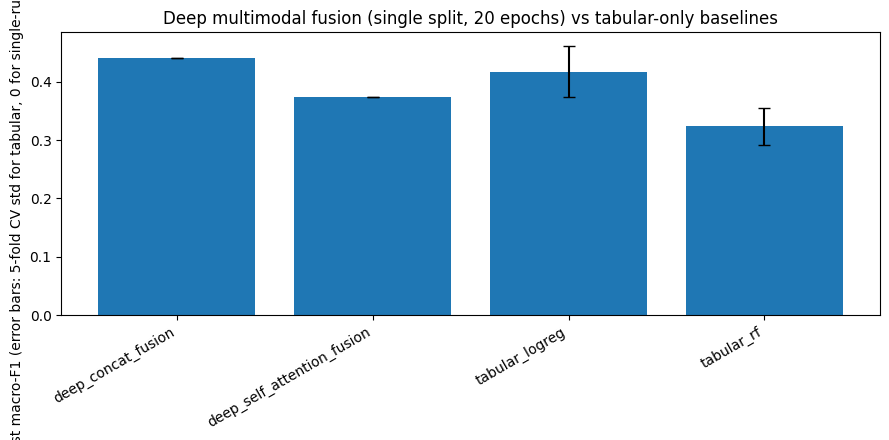


All outputs saved to: /kaggle/working/fydp-3_results/singlesplit_demo_fusion_test/2026-10-22


In [47]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(final_compare_df))
ax.bar(x, final_compare_df["f1_macro"], yerr=final_compare_df["f1_macro_std"], capsize=4)
ax.set_xticks(x)
ax.set_xticklabels(final_compare_df["model"], rotation=30, ha="right")
ax.set_ylabel("Test macro-F1 (error bars: 5-fold CV std for tabular, 0 for single-run deep models)")
ax.set_title("Deep multimodal fusion (single split, 20 epochs) vs tabular-only baselines")
plt.tight_layout()
final_png = os.path.join(RESULTS_DIR, "final_model_comparison_bar.png")
plt.savefig(final_png, dpi=150, bbox_inches="tight")
plt.show()

print("\nAll outputs saved to:", RESULTS_DIR)

## Step 14 — Zip Everything & Get a Download Link

Bundles every file written to `RESULTS_DIR` this run — training histories, test metrics, raw
probabilities, tabular-baseline results, confusion matrices, ROC curves, loss curves, the final
comparison table/bar chart, and both models' weights — into a single `.zip` in `/kaggle/working/`.


In [48]:
import shutil
from IPython.display import FileLink, display

zip_base = os.path.join(RESULTS_DIR_ROOT, f"fydp-3_singlesplit_results_{_run_date}")
zip_path = shutil.make_archive(zip_base, "zip", RESULTS_DIR)

print("Files bundled into the zip:")
for root, _, files in os.walk(RESULTS_DIR):
    for fn in sorted(files):
        full = os.path.join(root, fn)
        print(f"  {os.path.relpath(full, RESULTS_DIR)}  ({os.path.getsize(full) / 1024:.1f} KB)")

zip_size_mb = os.path.getsize(zip_path) / (1024 * 1024)
print(f"\nZip written to: {zip_path}  ({zip_size_mb:.1f} MB)")
print("Click below to download it (it's also visible under this notebook's Output tab):")
display(FileLink(os.path.relpath(zip_path, os.getcwd())))


Files bundled into the zip:
  concat_history.csv  (1.2 KB)
  concat_model.pt  (133548.1 KB)
  concat_test_metrics.json  (0.5 KB)
  concat_test_raw.npz  (2.9 KB)
  confusion_matrices.png  (36.0 KB)
  final_model_comparison.csv  (0.6 KB)
  final_model_comparison_bar.png  (65.9 KB)
  loss_curves_comparison.png  (108.1 KB)
  roc_curves_ovr.png  (85.5 KB)
  self_attention_history.csv  (1.2 KB)
  self_attention_model.pt  (135170.2 KB)
  self_attention_test_metrics.json  (0.5 KB)
  self_attention_test_raw.npz  (2.9 KB)
  tabular_baseline_results.json  (1.3 KB)

Zip written to: /kaggle/working/fydp-3_singlesplit_results_2026-10-22.zip  (243.7 MB)
Click below to download it (it's also visible under this notebook's Output tab):


/kaggle/working/fydp-3_singlesplit_results_2026-10-22.zip